# Step 3.4: Do the files link to each other?

**Run `step3_clean.ipynb` first.** This notebook reads the cleaned files in `data-clean/` and never changes them.

**Words you need**
- **Key / code:** the value that identifies a thing (`sku_code`, `stockist_code`, `batch_no`, `invoice_no`).
- **Master file:** the list of all valid things (`sku_master`, `stockist_master`, `batch_master`).
- **Orphan:** a row whose key does not exist in the master. Example: a claim for a batch that `batch_master` has never heard of.
- **Join:** combining two files on a shared key. If keys do not match, a join silently drops rows, so we test the keys first.

**Questions this notebook answers**
1. Does every SKU, stockist and batch used in a transaction file exist in its master?  *(3.4b)*
2. Do values stored in two places agree (C&F, expiry date, price, batch to SKU)?  *(3.4c)*
3. Can each expiry claim be traced back to what Pfizer actually sold?  *(3.4d)*
4. Does the picture match what we expected?  *(3.4g)*

## 3.4a Setup and load the cleaned files

In [9]:
import os
import numpy as np
import pandas as pd
from IPython.display import display, HTML
import matplotlib.pyplot as plt

CLEAN = os.path.join('..', 'data-clean')
AUD = os.path.join(CLEAN, 'audit', 'links'); os.makedirs(AUD, exist_ok=True)
if not os.path.exists(os.path.join(CLEAN, 'primary_sales.csv')):
    raise FileNotFoundError('Run step3_clean.ipynb first: data-clean/ is missing.')

names = ['sku_master','stockist_master','batch_master','primary_sales','expiry_claims','cnf_stock_snapshot','claim_emails']
L = {n: pd.read_csv(os.path.join(CLEAN, n + '.csv'), dtype=str, keep_default_na=False) for n in names}
sku, stk, bat, ps, ec, sn, em = (L[n] for n in names)
for n, d in L.items(): print(f'{n:22s} {len(d):>6} rows')

sku_master                 36 rows
stockist_master           156 rows
batch_master              663 rows
primary_sales           93063 rows
expiry_claims            4503 rows
cnf_stock_snapshot       5015 rows
claim_emails               30 rows


**Check:** `primary_sales 93063`, `expiry_claims 4503`, `cnf_stock_snapshot 5015`, `batch_master 663`, `sku_master 36`, `stockist_master 156`, `claim_emails 30`.

## 3.4b Does every code exist in its master? (orphan check)

For each pair we count the rows checked and the orphans. Blank keys are skipped (a blank batch means a cancelled line or a stock-out marker, already flagged in the cleaning step).

In [10]:
RES = []
def ref_check(name, child, col, parent_keys, note=''):
    c = child[child[col] != '']
    orph = c[~c[col].isin(set(parent_keys))]
    RES.append(dict(check=name, rows_checked=len(c), problems=len(orph), distinct_values=orph[col].nunique(), note=note))
    return orph

ref_check('primary_sales.sku_code -> sku_master', ps, 'sku_code', sku.sku_code)
ref_check('primary_sales.stockist_code -> stockist_master', ps, 'stockist_code', stk.stockist_code)
ref_check('primary_sales.batch_no -> batch_master', ps, 'batch_no', bat.batch_no)
ref_check('expiry_claims.sku_code -> sku_master', ec, 'sku_code', sku.sku_code)
ref_check('expiry_claims.stockist_code -> stockist_master', ec, 'stockist_code', stk.stockist_code)
orph_batch = ref_check('expiry_claims.batch_no -> batch_master', ec, 'batch_no', bat.batch_no, 'EXPLAINED in 3.4d: batches older than the data window')
ref_check('cnf_stock_snapshot.sku_code -> sku_master', sn, 'sku_code', sku.sku_code)
ref_check('cnf_stock_snapshot.batch_no -> batch_master', sn, 'batch_no', bat.batch_no)
ref_check('batch_master.sku_code -> sku_master', bat, 'sku_code', sku.sku_code)
ref_check('claim_emails.stockist_code -> stockist_master', em, 'stockist_code_by_mailbox_rule', stk.stockist_code)
pd.DataFrame(RES)

,check,rows_checked,problems,distinct_values,note
0,primary_sales.sku_code -> sku_master,93063,0,0,
1,primary_sales.stockist_code -> stockist_master,93063,0,0,
2,primary_sales.batch_no -> batch_master,90435,0,0,
3,expiry_claims.sku_code -> sku_master,4503,0,0,
4,expiry_claims.stockist_code -> stockist_master,4503,0,0,
5,expiry_claims.batch_no -> batch_master,4503,971,951,EXPLAINED in 3.4d: batches older than the data...
6,cnf_stock_snapshot.sku_code -> sku_master,5015,0,0,
7,cnf_stock_snapshot.batch_no -> batch_master,4745,0,0,
8,batch_master.sku_code -> sku_master,663,0,0,
9,claim_emails.stockist_code -> stockist_master,28,0,0,


**Check:** every line shows `problems = 0` except `expiry_claims.batch_no -> batch_master`, which shows **971** problems (951 different batch numbers). That is the one real gap; 3.4d explains it.

## 3.4c Do values stored in two places agree?

A fact stored twice must match. If it does not, one copy is wrong and every calculation using it is suspect.

In [11]:
CONS = []
def mismatch(name, n_checked, n_bad, note=''):
    CONS.append(dict(check=name, rows_checked=int(n_checked), problems=int(n_bad), note=note))

# C&F in a transaction = the stockist's home C&F in stockist_master
home = stk.set_index('stockist_code').cnf_code
for n, d in [('primary_sales', ps), ('expiry_claims', ec)]:
    mismatch(f'{n}.cnf_code = stockist home C&F', len(d), (d.cnf_code != d.stockist_code.map(home)).sum())

# a batch belongs to one SKU
b2s = bat.set_index('batch_no').sku_code
for n, d in [('primary_sales', ps), ('expiry_claims', ec), ('cnf_stock_snapshot', sn)]:
    x = d[(d.batch_no != '') & d.batch_no.isin(b2s.index)]
    mismatch(f'{n}: batch used with the SKU batch_master says', len(x), (x.batch_no.map(b2s) != x.sku_code).sum())

# expiry date copies
b2e = bat.set_index('batch_no').expiry_date
x = sn[(sn.batch_no != '') & sn.batch_no.isin(b2e.index)]
mismatch('cnf_stock_snapshot.expiry_date = batch_master.expiry_date', len(x), (x.expiry_date != x.batch_no.map(b2e)).sum())
x = ec[ec.batch_no.isin(b2e.index)]
mismatch('expiry_claims.expiry_date_as_claimed = batch_master.expiry_date', len(x), (x.expiry_date_as_claimed != x.batch_no.map(b2e)).sum())

# price copy
s2p = sku.set_index('sku_code').pts_inr.astype(float)
diff = (ps.pts_inr.astype(float) - ps.sku_code.map(s2p)).abs()
mismatch('primary_sales.pts_inr = sku_master.pts_inr', len(ps), (diff > 0.005).sum(), 'price master is one flat price per SKU; see open question R5')

# time order: invoice must fall between a batch's manufacture and expiry (dates are ISO text, so text order = date order)
m = ps[ps.batch_no != ''].merge(bat[['batch_no', 'mfg_date', 'expiry_date']], on='batch_no')
mismatch('primary_sales: invoice date before batch manufacture', len(m), (m.invoice_date < m.mfg_date).sum())
mismatch('primary_sales: invoice date after batch expiry', len(m), (m.invoice_date > m.expiry_date).sum())
pd.DataFrame(CONS)

,check,rows_checked,problems,note
0,primary_sales.cnf_code = stockist home C&F,93063,0,
1,expiry_claims.cnf_code = stockist home C&F,4503,0,
2,primary_sales: batch used with the SKU batch_m...,90435,0,
3,expiry_claims: batch used with the SKU batch_m...,3532,0,
4,cnf_stock_snapshot: batch used with the SKU ba...,4745,0,
5,cnf_stock_snapshot.expiry_date = batch_master....,4745,0,
6,expiry_claims.expiry_date_as_claimed = batch_m...,3532,0,
7,primary_sales.pts_inr = sku_master.pts_inr,93063,0,price master is one flat price per SKU; see op...
8,primary_sales: invoice date before batch manuf...,90435,0,
9,primary_sales: invoice date after batch expiry,90435,0,


**Check:** every `problems` value is **0**. (The price row notes that the price master is one flat price per SKU. Whether claims use the price on the claim date or today's price stays an open question for rule R5.)

## 3.4d Can each claim be traced to what Pfizer sold? (the 971 explained)

A claim is *traceable* when its batch is in `batch_master` **and** the same stockist was invoiced that batch. The pack explains the 971: `01` p3 §5.2 says `batch_master` *"covers batches manufactured from Oct 2023. Earlier batches were archived at ERP migration."* We still test that against the data rather than trust it: the sales extract starts on 1 Apr 2024, and `batch_master` only lists batches made from Oct 2023.

In [12]:
sales_keys = set(zip(ps.stockist_code, ps.batch_no))
inv = set(ps.invoice_no)
t = ec.copy()
t['batch_in_master'] = t.batch_no.isin(set(bat.batch_no))
t['stockist_was_invoiced_batch'] = [(s, b) in sales_keys for s, b in zip(t.stockist_code, t.batch_no)]
t['invoice_ref_given'] = t.original_invoice_ref != ''
t['invoice_ref_in_sales'] = t.original_invoice_ref.isin(inv)
t['batch_year_digits'] = t.batch_no.str[1:3]          # batch numbers carry the year: M2220205 -> 22

conds = [
    t.batch_in_master & t.stockist_was_invoiced_batch & t.invoice_ref_given & t.invoice_ref_in_sales,
    t.batch_in_master & t.stockist_was_invoiced_batch & ~t.invoice_ref_given,
    ~t.batch_in_master & t.invoice_ref_given,
    ~t.batch_in_master & ~t.invoice_ref_given,
]
labels = ['A traceable: invoice ref found in sales', 'B traceable by stockist+batch only (no invoice ref)',
          'C older batch: ref given, invoice not in extract', 'D older batch: no invoice ref']
t['trace_category'] = np.select(conds, labels, default='E OTHER: investigate')
t['claim_value_inr'] = pd.to_numeric(t.claim_value_inr)

summ = t.groupby('trace_category').agg(claims=('claim_no', 'size'), value_inr=('claim_value_inr', 'sum')).reset_index()
summ['share_of_claims_%'] = (summ.claims / len(t) * 100).round(1)
summ['value_inr_lakh'] = (summ.value_inr / 1e5).round(1)
display(summ.drop(columns='value_inr'))

# invoice numbers carry yymm: refs missing from sales should all be older than the extract (before 2404 = Apr 2024)
CUT = '2404'
ref = t[t.original_invoice_ref != ''].copy()
ref['ref_month'] = ref.original_invoice_ref.str.split('/').str[2]
nf = ref[~ref.invoice_ref_in_sales]
print(f'invoice refs given: {len(ref)} | found in sales: {int(ref.invoice_ref_in_sales.sum())} | not found: {len(nf)} | not found AND dated before {CUT}: {int((nf.ref_month < CUT).sum())} | not found but inside the sales window: {int((nf.ref_month >= CUT).sum())}')

o = t[~t.batch_in_master]
# test the idea that digits 2-3 of a batch number are its manufacturing year, using the batches we DO know
conv = int((bat.batch_no.str[1:3] == bat.mfg_date.str[2:4]).sum())
print(f'batch-number year digits = manufacturing year in batch_master: {conv} of {len(bat)}   (so reading 22 as 2022 is an inference that holds wherever we can test it)')
assert conv == len(bat)
print('Older-batch claims (C + D):')
print('  batch year digits   :', o.batch_year_digits.value_counts().sort_index().to_dict(), '  (batch_master has only 23-26)')
print('  claim date range    :', o.claim_date.min(), 'to', o.claim_date.max())
print('  expiry as claimed   :', o.expiry_date_as_claimed.min(), 'to', o.expiry_date_as_claimed.max())
print('  sales extract starts:', ps.invoice_date.min())
print('  status              :', o.status.value_counts().to_dict())
print('  claim types         :', o.claim_type.value_counts().to_dict())
cred = pd.to_numeric(t.credit_value_inr, errors='coerce')
print(f'  credited INR (older batches): {cred[~t.batch_in_master].sum():,.0f} = {cred[~t.batch_in_master].sum() / cred.sum() * 100:.1f}% of all credited INR')

,trace_category,claims,share_of_claims_%,value_inr_lakh
0,A traceable: invoice ref found in sales,2856,63.4,579.8
1,B traceable by stockist+batch only (no invoice...,676,15.0,132.7
2,"C older batch: ref given, invoice not in extract",768,17.1,68.7
3,D older batch: no invoice ref,203,4.5,13.7


invoice refs given: 3624 | found in sales: 2856 | not found: 768 | not found AND dated before 2404: 768 | not found but inside the sales window: 0
batch-number year digits = manufacturing year in batch_master: 663 of 663   (so reading 22 as 2022 is an inference that holds wherever we can test it)
Older-batch claims (C + D):
  batch year digits   : {'22': 675, '23': 296}   (batch_master has only 23-26)
  claim date range    : 2024-07-01 to 2025-03-27
  expiry as claimed   : 2024-05-31 to 2025-06-30
  sales extract starts: 2024-04-01
  status              : {'Credited': 971}
  claim types         : {'Near expiry': 693, 'Expired': 278}
  credited INR (older batches): 8,544,541 = 11.9% of all credited INR


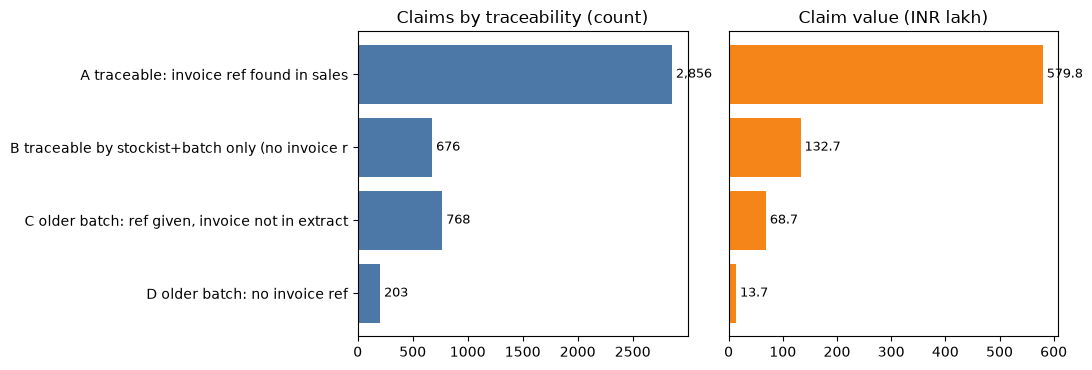

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
s2 = summ.sort_values('trace_category', ascending=False)
axes[0].barh(s2.trace_category.str[:48], s2.claims, color='#4c78a8')
for i, v in enumerate(s2.claims): axes[0].text(v, i, f' {v:,}', va='center', fontsize=9)
axes[0].set_title('Claims by traceability (count)')
axes[1].barh(s2.trace_category.str[:48], s2.value_inr_lakh, color='#f58518')
for i, v in enumerate(s2.value_inr_lakh): axes[1].text(v, i, f' {v:,.1f}', va='center', fontsize=9)
axes[1].set_yticks([]); axes[1].set_title('Claim value (INR lakh)')
plt.tight_layout(); plt.show()

**How to read this:** categories A and B (3,532 claims) link all the way to a real sales line, so the rule tests in Step 4 (quantity, window, value) can run on them. Categories C and D (971 claims, all already **Credited**) are about batches made in 2022-23, before the extract begins. They cannot be tested against sales. They are untraceable *with this data*, which is not the same as wrong.

## 3.4e Coverage and date ranges

Does every master SKU and stockist actually appear in the transactions, and do the files cover the same period?

In [14]:
print('SKUs in master not in sales          :', sorted(set(sku.sku_code) - set(ps.sku_code)))
print('stockists in master with no sales    :', len(set(stk.stockist_code) - set(ps.stockist_code)))
print('stockists with no claims             :', len(set(stk.stockist_code) - set(ec.stockist_code)))
for n_, df_, c_ in [('primary_sales', ps, 'invoice_date'), ('expiry_claims', ec, 'claim_date'), ('snapshot', sn, 'snapshot_date'),
                    ('claim_emails', em, 'received_date'), ('batch mfg', bat, 'mfg_date'), ('batch expiry', bat, 'expiry_date')]:
    s_ = df_[c_][df_[c_] != '']
    print(f'{n_:14s} {s_.min()}  to  {s_.max()}')

SKUs in master not in sales          : []
stockists in master with no sales    : 0
stockists with no claims             : 2
primary_sales  2024-04-01  to  2026-09-30
expiry_claims  2024-04-18  to  2026-09-30
snapshot       2024-06-30  to  2026-09-30
claim_emails   2026-10-01  to  2026-10-16
batch mfg      2023-10-01  to  2026-09-06
batch expiry   2025-03-31  to  2029-08-31


**Check:** sales Apr 2024 - Sep 2026; claims Apr 2024 - Sep 2026; snapshots Jun 2024 - Sep 2026; emails 1-16 Oct 2026. Every SKU and stockist has sales; 2 stockists have no claims.

## 3.4f Save the evidence

In [15]:
keep = ['claim_no','claim_date','stockist_code','cnf_code','sku_code','batch_no','claim_type','status','claim_value_inr',
        'original_invoice_ref','batch_in_master','stockist_was_invoiced_batch','invoice_ref_given','invoice_ref_in_sales','batch_year_digits','trace_category']
t[keep].to_csv(os.path.join(AUD, 'claims_traceability.csv'), index=False)
res = pd.concat([pd.DataFrame(RES).assign(group='orphan check'), pd.DataFrame(CONS).assign(group='consistency check')], ignore_index=True)
res['status'] = np.where(res.problems == 0, 'OK', np.where(res.note.str.startswith('EXPLAINED'), 'EXPLAINED', 'CHECK'))
res.to_csv(os.path.join(AUD, 'link_check_summary.csv'), index=False)
summ.to_csv(os.path.join(AUD, 'claims_traceability_summary.csv'), index=False)
print('written to', os.path.abspath(AUD))
res[['group', 'check', 'rows_checked', 'problems', 'status']]

written to d:\FDE\Assignments\langgraph\pfizer-channel-engagement_learner-pack\data-clean\audit\links


,group,check,rows_checked,problems,status
0,orphan check,primary_sales.sku_code -> sku_master,93063,0,OK
1,orphan check,primary_sales.stockist_code -> stockist_master,93063,0,OK
2,orphan check,primary_sales.batch_no -> batch_master,90435,0,OK
3,orphan check,expiry_claims.sku_code -> sku_master,4503,0,OK
4,orphan check,expiry_claims.stockist_code -> stockist_master,4503,0,OK
5,orphan check,expiry_claims.batch_no -> batch_master,4503,971,EXPLAINED
6,orphan check,cnf_stock_snapshot.sku_code -> sku_master,5015,0,OK
7,orphan check,cnf_stock_snapshot.batch_no -> batch_master,4745,0,OK
8,orphan check,batch_master.sku_code -> sku_master,663,0,OK
9,orphan check,claim_emails.stockist_code -> stockist_master,28,0,OK


## 3.4g Validate: is the picture what we expected?

In [16]:
assert len(t) == 4503
assert (res.status != 'CHECK').all(), res[res.status == 'CHECK']
assert (res[res.group == 'consistency check'].problems == 0).all()
assert len(orph_batch) == 971 and orph_batch.batch_no.nunique() == 951
assert (t.trace_category != 'E OTHER: investigate').all(), 'unexpected claim category'
# every claim whose batch IS in master was invoiced to that stockist, and every quoted invoice ref exists in sales
assert t[t.batch_in_master].stockist_was_invoiced_batch.all()
assert t[t.batch_in_master & t.invoice_ref_given].invoice_ref_in_sales.all()
# the invoice refs missing from sales are exactly the older-batch claims
assert (~t[t.invoice_ref_given & ~t.invoice_ref_in_sales].batch_in_master).all()
# older batches are all made before the earliest batch in batch_master (2023)
assert (o.batch_year_digits.astype(int) <= 23).all() and (o.batch_year_digits.astype(int) < 23).any()
assert int(ref.invoice_ref_in_sales.sum()) == 2856 and len(nf) == 768
assert int((nf.ref_month >= CUT).sum()) == 0          # no invoice ref inside the sales window is missing from sales
print(t.trace_category.value_counts().sort_index().to_string())
print('ALL LINK CHECKS PASSED')

trace_category
A traceable: invoice ref found in sales                2856
B traceable by stockist+batch only (no invoice ref)     676
C older batch: ref given, invoice not in extract        768
D older batch: no invoice ref                           203
ALL LINK CHECKS PASSED


**Check:** counts printed are `A` **2,856**, `B` **676**, `C` **768**, `D` **203**, and the last line reads `ALL LINK CHECKS PASSED`.

Files written to `data-clean/audit/links/`: `link_check_summary.csv`, `claims_traceability.csv`, `claims_traceability_summary.csv`.
Next: 3.5 data dictionary and data-quality log, then 3.6 reproduce the QBR numbers.